# Wolfire et al. (1995) の検証計算

`test/test.out` が出力した平衡状態から、水素密度に対する圧力・電離分率と、温度に対する平均分子量を描きます。計算方法は [README](../README.md#wolfire-et-al-1995-の検証計算と描画) にあります。

## 計算結果の指定

標準の実行先は `test/out/wolfire` です。保存済みの実行を使う場合は `run_dir` にそのディレクトリを指定してください。出力ファイルは `out/`、`results/`、実行ディレクトリ直下の順に探します。保存済みの `rejected.tsv` があれば、求解に失敗した点も表で表示します。

In [1]:
from functools import lru_cache
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
repo_root = next(
    (directory for directory in (cwd, *cwd.parents)
     if (directory / "plot" / "PlotWolfire1995.ipynb").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("CEQLib のリポジトリ内からノートブックを実行してください。")

run_dir = repo_root / "test" / "out" / "wolfire"

## 結果の読み込みと比較条件

出力列の対応は [test/main.c](../test/main.c) の `main_WolfireTestBody` に従います。図ごとに使う列は、温度 `T` と水素・電子・イオンの数密度です。

In [2]:
def result_file(column=1e19, isrf=1.0, metallicity=1.0, *, abundances=None, x0=None):
    name = f"PostProcessMap_Nt{column:.1e}_ISRF{isrf:.1f}_Zs{metallicity:.1e}"
    if abundances is not None:
        carbon, oxygen = abundances
        name += f"_Ac{carbon:.1e}_Ao{oxygen:.1e}"
    if x0 is not None:
        name += f"_Xo{x0:.1f}"
    return name + ".dat"


reference = result_file()
data_dir = next(
    (directory for directory in (run_dir / "out", run_dir / "results", run_dir)
     if (directory / reference).is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        f"{run_dir} に {reference} が見つかりません。"
        "run_dir を確認するか、README の手順で計算してください。"
    )

# Zero-based column indices in the headerless PostProcessMap files.
result_columns = {8: "T", 12: "n_H", 16: "n_e", 17: "n_HII", 18: "n_HI"}


@lru_cache(maxsize=None)
def read_result(filename):
    path = data_dir / filename
    if not path.is_file():
        raise FileNotFoundError(f"比較に必要な計算結果が見つかりません。{path}")
    return pd.read_csv(
        path, sep=r"\s+", header=None, usecols=list(result_columns)
    ).rename(columns=result_columns)


rejected_path = run_dir / "rejected.tsv"
if rejected_path.is_file():
    rejected = pd.read_csv(rejected_path, sep="	").sort_values(["case", "sample"])
    display(rejected[["case", "sample", "nH_cm^-3", "T_K", "status"]].reset_index(drop=True))

,case,sample,nH_cm^-3,T_K,status
0,1,0,0.001000,2253.53,-2
1,1,1,0.001148,2716.00,-2
2,1,2,0.001318,3263.12,-2
3,1,3,0.001514,3910.88,-2
4,1,4,0.001738,4675.23,-2
5,1,5,0.001995,5577.19,-2
6,1,6,0.002291,6642.51,-2
7,1,7,0.002630,7889.53,-2
8,1,8,0.003020,9342.72,-2


In [3]:
panels = [
    (
        r"Column density (ISRF = 1, $Z=Z_\odot$)",
        [(result_file(column=10.0**exponent), rf"$N_{{\rm tot}}=10^{{{exponent}}}$" + r" cm$^{-2}$")
         for exponent in (19, 18, 20)],
    ),
    (
        r"Metallicity ($N_{\rm tot}=10^{19}$ cm$^{-2}$, ISRF = 1)",
        [(result_file(metallicity=z), rf"$Z/Z_\odot={z:g}$")
         for z in (1, 0.01, 0.03, 0.1, 0.3, 3)],
    ),
    (
        r"Radiation field ($N_{\rm tot}=10^{19}$ cm$^{-2}$, $Z=Z_\odot$)",
        [(result_file(isrf=isrf), f"ISRF = {isrf:g}")
         for isrf in (1, 0.3, 0.5, 3, 10, 100, 1000)],
    ),
    (
        r"C and O abundances ($N_{\rm tot}=10^{19}$ cm$^{-2}$, ISRF = 1, $Z=Z_\odot$)",
        [(result_file(abundances=(carbon, oxygen)), rf"$A_{{\rm C}}={carbon:g}, A_{{\rm O}}={oxygen:g}$")
         for carbon, oxygen in ((1, 1), (0.1, 1), (0.5, 0.65), (1, 1.7), (0.5, 1))],
    ),
]

plt.rcParams.update({
    "axes.labelsize": 13,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
})

density_label = r"$\log_{10}[n_{\rm H}/(\mathrm{cm}^{-3})]$"


def log10_positive(values):
    return np.log10(values.where(values > 0))


def plot_density_panels(quantity, ylabel, *, xlim, ylim=None):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
    for ax, (title, cases) in zip(axes.flat, panels):
        for index, (filename, label) in enumerate(cases):
            data = read_result(filename)
            ax.plot(
                log10_positive(data["n_H"]), quantity(data),
                label=label, color="black" if index == 0 else None,
                linewidth=2.6 if index == 0 else 1.7,
            )
        ax.set(title=title, xlabel=density_label, ylabel=ylabel, xlim=xlim, ylim=ylim)
        ax.legend()
        ax.grid(alpha=0.3)
    plt.show()

## 平衡圧力と水素密度

圧力に対応する量として水素核数密度と温度の積 $n_{\rm H}T$ を表示します。柱密度、金属量、ISRF、炭素・酸素存在量をそれぞれ変えた結果を比較します。

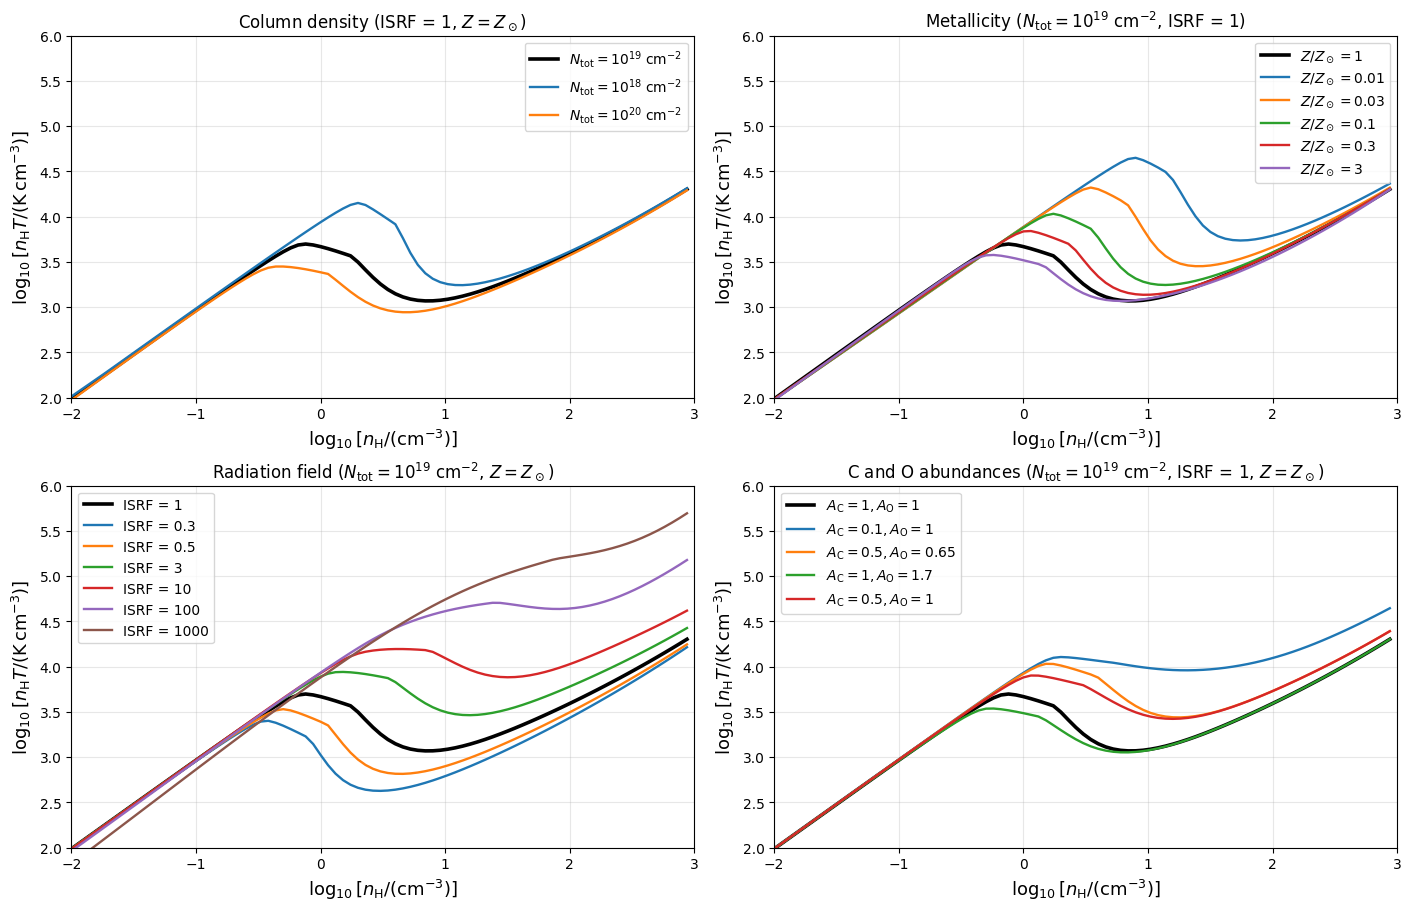

In [4]:
plot_density_panels(
    lambda data: log10_positive(data["n_H"] * data["T"]),
    r"$\log_{10}[n_{\rm H}T/(\mathrm{K\,cm}^{-3})]$",
    xlim=(-2, 3), ylim=(2, 6),
)

## 放射場スケーリング $X_0$ による規格化

この比較では、試験コードが $X_0$ と ISRF を同じ倍率で変えています。横軸は $n_{\rm H}/X_0$、縦軸は $n_{\rm H}T/X_0$ です。

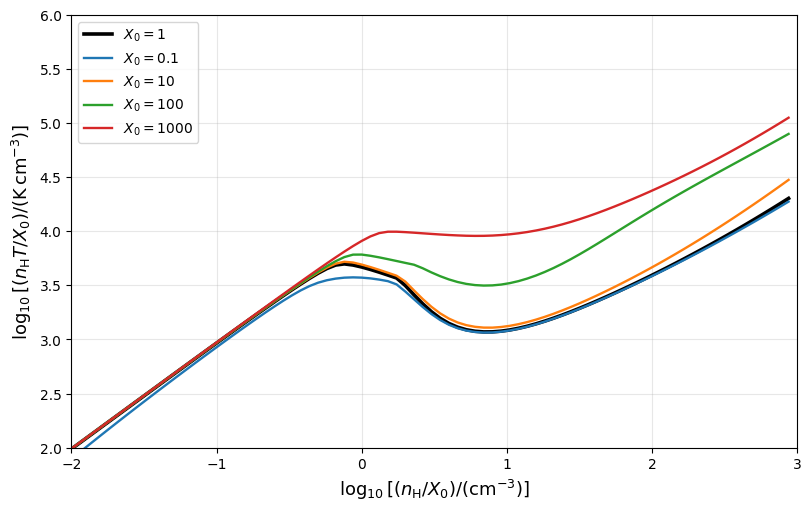

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for x0 in (1, 0.1, 10, 100, 1000):
    data = read_result(result_file(isrf=x0, x0=x0))
    scaled_density = data["n_H"] / x0
    ax.plot(
        log10_positive(scaled_density), log10_positive(scaled_density * data["T"]),
        label=rf"$X_0={x0:g}$", color="black" if x0 == 1 else None,
        linewidth=2.6 if x0 == 1 else 1.7,
    )
ax.set(
    xlabel=r"$\log_{10}[(n_{\rm H}/X_0)/(\mathrm{cm}^{-3})]$",
    ylabel=r"$\log_{10}[(n_{\rm H}T/X_0)/(\mathrm{K\,cm}^{-3})]$",
    xlim=(-2, 3), ylim=(2, 6),
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 水素の電離分率と中性分率

H II の分率 $n_{\rm HII}/n_{\rm H}$ を対数、H I の分率 $n_{\rm HI}/n_{\rm H}$ を線形目盛で表示します。電子分率 $x_e=n_e/n_{\rm H}$ は次節に示します。

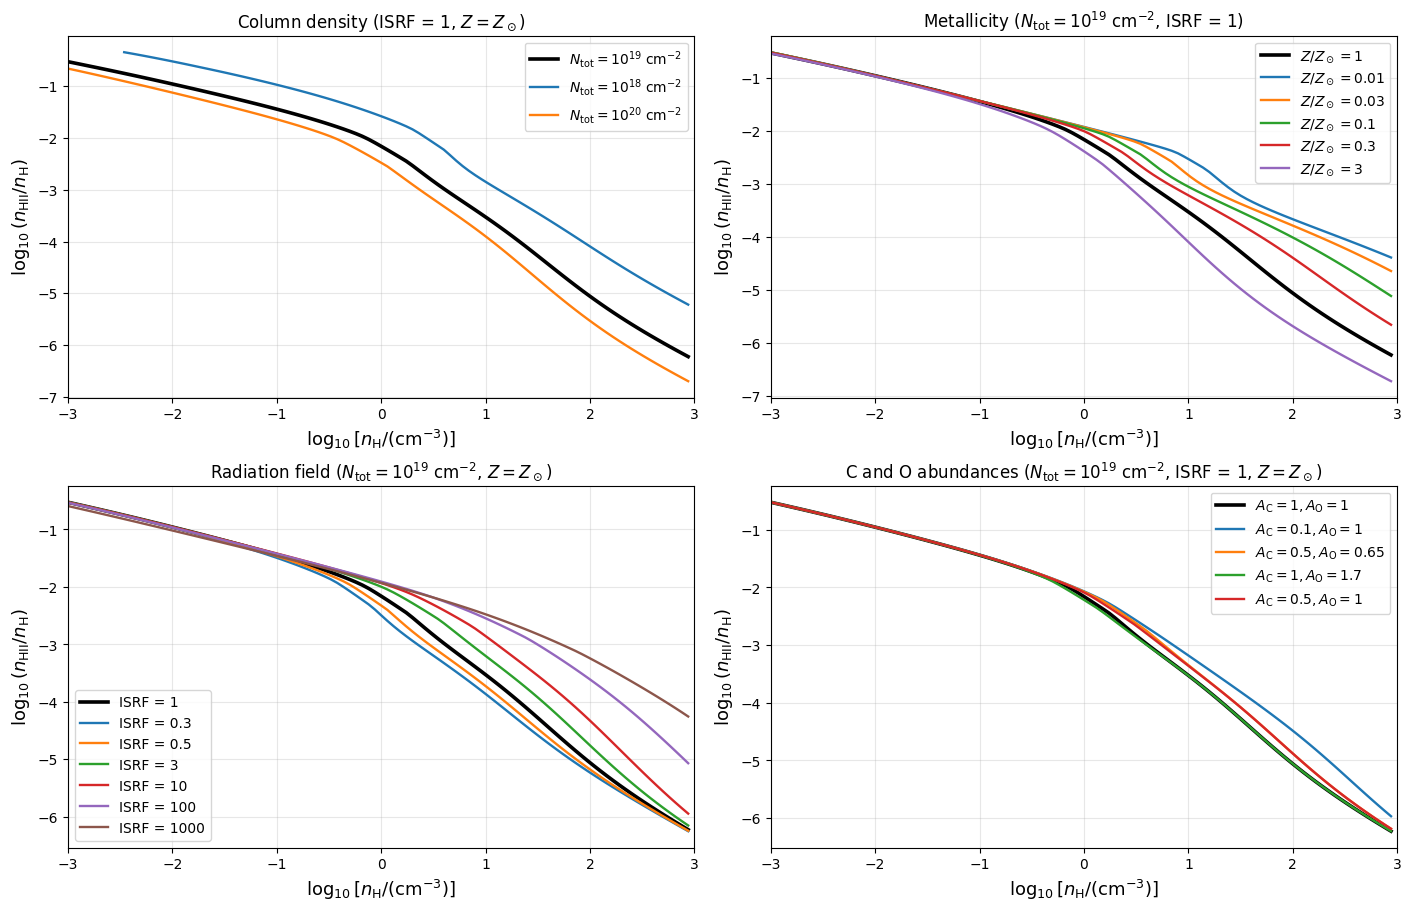

In [6]:
plot_density_panels(
    lambda data: log10_positive(data["n_HII"] / data["n_H"]),
    r"$\log_{10}(n_{\rm HII}/n_{\rm H})$",
    xlim=(-3, 3),
)

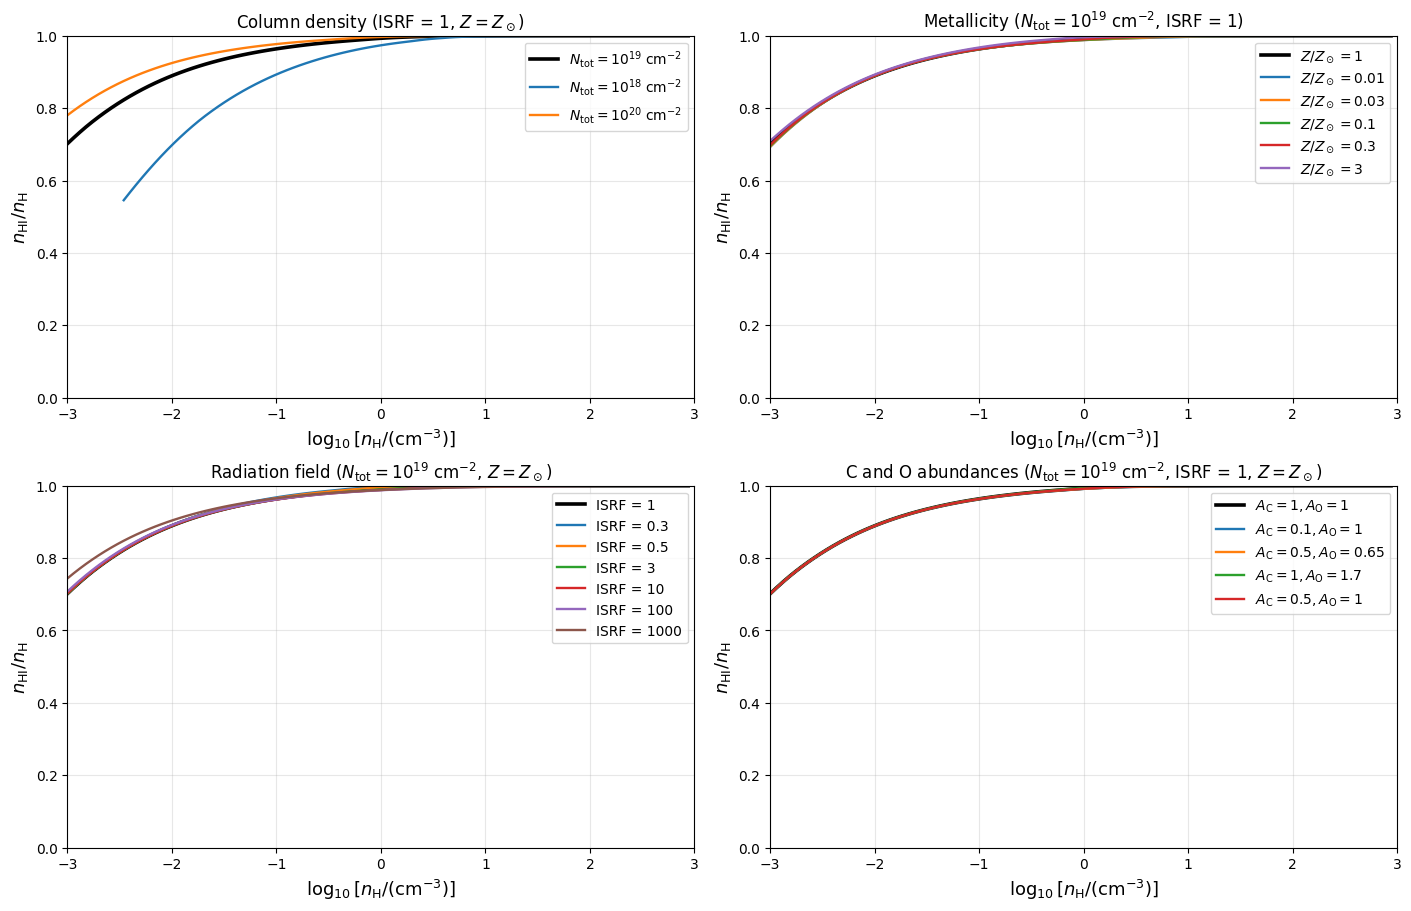

In [7]:
plot_density_panels(
    lambda data: data["n_HI"] / data["n_H"],
    r"$n_{\rm HI}/n_{\rm H}$",
    xlim=(-3, 3), ylim=(0, 1),
)

## 平均分子量と電子分率

$y_{\rm He}=n_{\rm He}/n_{\rm H}=0.1$ の原子・イオンガスとして、平均分子量を $\mu=(1+4y_{\rm He})/(1+y_{\rm He}+x_e)$ で求めます。$x_e$ は出力された電子数密度から計算します。水平線は中性、H のみ電離、完全電離の各極限です。

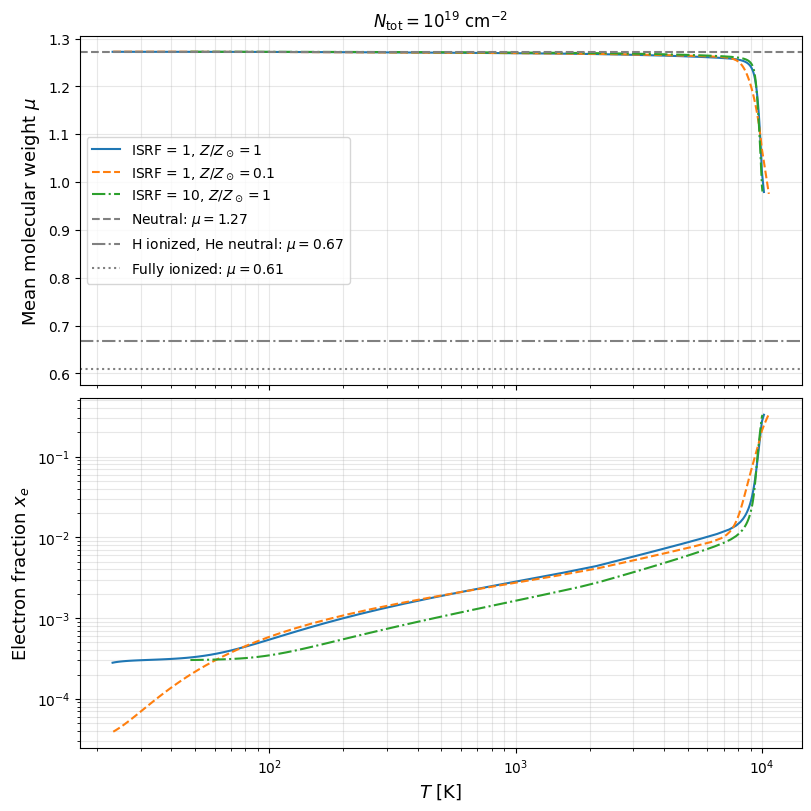

In [8]:
models = [
    (reference, r"ISRF = 1, $Z/Z_\odot=1$", "-"),
    (result_file(metallicity=0.1), r"ISRF = 1, $Z/Z_\odot=0.1$", "--"),
    (result_file(isrf=10), r"ISRF = 10, $Z/Z_\odot=1$", "-."),
]

y_he = 0.1
mass_per_h = 1 + 4 * y_he
fig, (ax_mu, ax_xe) = plt.subplots(
    2, 1, figsize=(8, 8), sharex=True, layout="constrained",
)
for filename, label, style in models:
    data = read_result(filename).sort_values("T")
    xe = data["n_e"] / data["n_H"]
    mu = mass_per_h / (1 + y_he + xe)
    line, = ax_mu.semilogx(data["T"], mu, linestyle=style, label=label)
    ax_xe.loglog(data["T"], xe, color=line.get_color(), linestyle=style)

limits = [
    (1 + y_he, "Neutral", "--"),
    (2 + y_he, "H ionized, He neutral", "-."),
    (2 + 3 * y_he, "Fully ionized", ":"),
]
for particles, label, style in limits:
    mu_limit = mass_per_h / particles
    ax_mu.axhline(mu_limit, color="gray", linestyle=style, label=rf"{label}: $\mu={mu_limit:.2f}$")

ax_mu.set(title=r"$N_{\rm tot}=10^{19}$ cm$^{-2}$", ylabel=r"Mean molecular weight $\mu$")
ax_xe.set(xlabel=r"$T$ [K]", ylabel=r"Electron fraction $x_e$")
for ax in (ax_mu, ax_xe):
    ax.grid(which="both", alpha=0.3)
ax_mu.legend()
plt.show()